# T35 — Brain Tumor MRI Classification with PyTorch

**AI Platforms · Assignment 1 · Team T35**

**Dataset:** [Masoud Nickparvar — Brain Tumor MRI Dataset](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset)  
**Classes (fixed order):** `glioma`, `meningioma`, `notumor`, `pituitary`  
**Deployed model:** ImageNet-pretrained **ResNet18** → `model/model_T35.pt` (PyTorch `state_dict`, CPU-compatible, offline).


## 0. Environment & repository layout

The notebook lives in `notebooks/` and expects this repository layout:

```
brain-tumor-detection/
├── app/            (config.py, main.py)
├── data/
│   ├── Training/{glioma,meningioma,notumor,pituitary}/
│   └── Testing/{glioma,meningioma,notumor,pituitary}/
├── model/          ← this notebook writes model_T35.pt here
├── notebooks/      ← pytorch_T35.ipynb (this file)
└── requirements.txt
```

**Nothing but `model/model_T35.pt` is written inside the repository.** Figures, the split manifest, metrics and metadata go to a sibling folder `T35_work/` (outside the repo) so the submission ZIP keeps exactly the required structure.

In [1]:
import os
import json
import time
import copy
import random
import hashlib
import platform
from pathlib import Path
from contextlib import nullcontext
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from torchvision.transforms import InterpolationMode
from torchvision.models import ResNet18_Weights, ResNet50_Weights

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

# ---------------- fixed settings ----------------
TEAM_ID = 'T35'
CLASS_NAMES = ['glioma', 'meningioma', 'notumor', 'pituitary']
IMAGE_SIZE = 224
SEED = 42

# ---------------- training settings ----------------
BATCH_SIZE = 16          # use 8 if CUDA runs out of memory
NUM_WORKERS = 0          # safest on Windows / Jupyter
HEAD_EPOCHS = 6          # frozen-backbone stage (max, early stopping applies)
FINETUNE_EPOCHS = 12     # fine-tuning stage (max, early stopping applies)
HEAD_PATIENCE = 3
FINETUNE_PATIENCE = 4
RUN_RESNET50_COMPARISON = True   # second architecture, comparison only (validation set)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'

ENVIRONMENT = {
    'python': platform.python_version(),
    'pytorch': torch.__version__,
    'torchvision': __import__('torchvision').__version__,
    'cuda_build': torch.version.cuda,
    'device': str(DEVICE),
    'gpu': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
    'vram_gib': round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2)
                if DEVICE.type == 'cuda' else None,
    'amp': USE_AMP,
    'batch_size': BATCH_SIZE,
    'seed': SEED,
}
for key, value in ENVIRONMENT.items():
    print(f'{key:12s}: {value}')
if DEVICE.type != 'cuda':
    print('WARNING: CUDA is not active. Training will be much slower on the CPU.')

c:\Users\Ahmed Kazak\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


python      : 3.12.1
pytorch     : 2.11.0+cu126
torchvision : 0.26.0+cu126
cuda_build  : 12.6
device      : cuda
gpu         : NVIDIA GeForce RTX 3050 Ti Laptop GPU
vram_gib    : 4.0
amp         : True
batch_size  : 16
seed        : 42


## 1. Locate the dataset and output folders

The notebook is run from `notebooks/`, so the project root is its parent. The dataset must already be extracted to `data/Training/...` and `data/Testing/...` (override with the `BRAIN_MRI_DATA_DIR` environment variable). Sample counts below are computed from **your local files**.

In [2]:
HERE = Path.cwd().resolve()
PROJECT_ROOT = HERE.parent if HERE.name.lower() == 'notebooks' else HERE
MODEL_DIR = PROJECT_ROOT / 'model'
MODEL_DIR.mkdir(exist_ok=True)

# Everything except model_T35.pt is written OUTSIDE the repo, next to it.
WORK_DIR = Path(os.environ.get('T35_WORK_DIR', PROJECT_ROOT.parent / f'{TEAM_ID}_work')).resolve()
WORK_DIR.mkdir(parents=True, exist_ok=True)

explicit_root = os.environ.get('BRAIN_MRI_DATA_DIR', '').strip()
candidate_roots = ([Path(explicit_root).expanduser()] if explicit_root else []) + [
    PROJECT_ROOT / 'data',
    PROJECT_ROOT / 'data' / 'brain-tumor-mri-dataset',
]


def is_dataset_root(path):
    return (path / 'Training').is_dir() and (path / 'Testing').is_dir()


def locate_dataset(candidates):
    for parent in candidates:
        if is_dataset_root(parent):
            return parent.resolve()
        if parent.is_dir():
            for child in sorted(parent.iterdir()):
                if child.is_dir() and is_dataset_root(child):
                    return child.resolve()
    raise FileNotFoundError(
        f'Could not find Training/ and Testing/. Extract the Kaggle dataset into '
        f'{PROJECT_ROOT / "data"} or set BRAIN_MRI_DATA_DIR.'
    )


DATASET_ROOT = locate_dataset(candidate_roots)
TRAIN_DIR = DATASET_ROOT / 'Training'
TEST_DIR = DATASET_ROOT / 'Testing'
MODEL_PATH = MODEL_DIR / f'model_{TEAM_ID}.pt'

print('Project root :', PROJECT_ROOT)
print('Dataset      :', DATASET_ROOT)
print('Model file   :', MODEL_PATH)
print('Work folder  :', WORK_DIR, '(outside the repo; figures, splits, metrics)')

Project root : C:\Users\Ahmed Kazak\AI_Security\brain-tumor-detection
Dataset      : C:\Users\Ahmed Kazak\AI_Security\brain-tumor-detection\data
Model file   : C:\Users\Ahmed Kazak\AI_Security\brain-tumor-detection\model\model_T35.pt
Work folder  : C:\Users\Ahmed Kazak\AI_Security\T35_work (outside the repo; figures, splits, metrics)


## 2. Preprocessing and conservative augmentation

- Every image is converted to **RGB** (the pretrained backbone needs 3 channels) and resized to 224×224.
- **Training only:** small random rotation (±8°) and translation (≤3 %). No horizontal flips (they would swap left/right anatomy) and no aggressive crops (they can cut out the tumour).
- **Validation / test / API:** identical deterministic pipeline — resize → tensor → ImageNet mean/std normalization.

Label-to-index mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


,class,full_training_folder,testing_folder
0,glioma,1400,400
1,meningioma,1400,400
2,notumor,1400,400
3,pituitary,1400,400


Training folder total: 5600
Testing folder total : 1600

Most common (width, height) in a 300-image sample:
(512, 512)    216
(225, 225)      9
(630, 630)      9
(442, 442)      4
(236, 236)      3


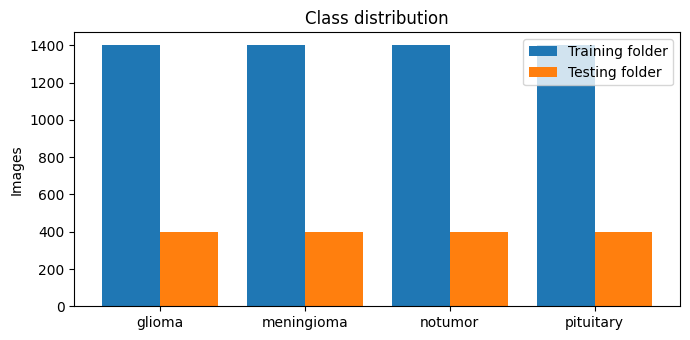

In [3]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomAffine(degrees=8, translate=(0.03, 0.03), fill=0),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

raw_train = datasets.ImageFolder(TRAIN_DIR)
train_source = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
val_source = datasets.ImageFolder(TRAIN_DIR, transform=eval_transform)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transform)

assert raw_train.classes == CLASS_NAMES, f'Training labels: {raw_train.classes}'
assert test_dataset.classes == CLASS_NAMES, f'Testing labels: {test_dataset.classes}'
assert train_source.class_to_idx == val_source.class_to_idx == test_dataset.class_to_idx
assert len(raw_train) > 0 and len(test_dataset) > 0

print('Label-to-index mapping:', raw_train.class_to_idx)
counts = pd.DataFrame({
    'class': CLASS_NAMES,
    'full_training_folder': np.bincount(raw_train.targets, minlength=4),
    'testing_folder': np.bincount(test_dataset.targets, minlength=4),
})
display(counts)
print('Training folder total:', len(raw_train))
print('Testing folder total :', len(test_dataset))

# Image-size EDA on a small random sample (MRI slices come in different resolutions).
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(len(raw_train), size=min(300, len(raw_train)), replace=False)
sizes = []
for i in sample_ids:
    with Image.open(raw_train.samples[int(i)][0]) as im:
        sizes.append(im.size)
size_counts = pd.Series(sizes).value_counts().head(5)
print('\nMost common (width, height) in a 300-image sample:')
print(size_counts.to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(np.arange(4) - 0.2, counts['full_training_folder'], 0.4, label='Training folder')
ax.bar(np.arange(4) + 0.2, counts['testing_folder'], 0.4, label='Testing folder')
ax.set_xticks(range(4))
ax.set_xticklabels(CLASS_NAMES)
ax.set(ylabel='Images', title='Class distribution')
ax.legend()
fig.tight_layout()
fig.savefig(WORK_DIR / f'class_distribution_{TEAM_ID}.png', dpi=170, bbox_inches='tight')
plt.show()

## 3. Leakage checks and grouped, stratified train/validation split

SHA-256 fingerprints catch **exact** duplicate files. `StratifiedGroupKFold` keeps identical training files in the same split while approximately preserving class proportions (≈ 80 % train / 20 % validation). It **cannot** detect near-duplicates or identify patients, which is a limitation to discuss in the report.

Any exact duplicates between the official `Training/` and `Testing/` folders are **reported, not deleted**. The split manifest stores relative file paths so the TensorFlow notebook can reuse precisely the same samples.

In [4]:
def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


train_hashes = [file_sha256(p) for p, _ in tqdm(raw_train.samples, desc='Hash train files')]
test_hashes = [file_sha256(p) for p, _ in tqdm(test_dataset.samples, desc='Hash test files')]

dupes_within_train = len(train_hashes) - len(set(train_hashes))
train_test_duplicate_hashes = set(train_hashes) & set(test_hashes)
print('Exact duplicate files inside Training:', dupes_within_train)
print('Exact duplicate files shared by Training and Testing:', len(train_test_duplicate_hashes))
if train_test_duplicate_hashes:
    print('WARNING: Training and Testing share identical files; '
          'do not claim the test evaluation is fully independent.')

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
labels = np.asarray(raw_train.targets, dtype=int)
train_indices, val_indices = next(sgkf.split(np.arange(len(raw_train)), labels, groups=train_hashes))

hash_array = np.asarray(train_hashes)
assert set(train_indices).isdisjoint(set(val_indices))
assert not (set(hash_array[train_indices]) & set(hash_array[val_indices])), 'Duplicate leak across split'
assert sorted(set(labels[train_indices])) == list(range(4)), 'Training split is missing a class'
assert sorted(set(labels[val_indices])) == list(range(4)), 'Validation split is missing a class'

train_dataset = Subset(train_source, train_indices.tolist())
val_dataset = Subset(val_source, val_indices.tolist())

split_counts = pd.DataFrame({
    'class': CLASS_NAMES,
    'train': np.bincount(labels[train_indices], minlength=4),
    'validation': np.bincount(labels[val_indices], minlength=4),
    'test': np.bincount(test_dataset.targets, minlength=4),
})
split_counts.loc[len(split_counts)] = ['TOTAL', len(train_dataset), len(val_dataset), len(test_dataset)]
display(split_counts)
print('Train / validation / test:', len(train_dataset), len(val_dataset), len(test_dataset))
split_counts.to_csv(WORK_DIR / f'split_counts_{TEAM_ID}.csv', index=False)


def rel_train(idx):
    return Path(raw_train.samples[int(idx)][0]).relative_to(TRAIN_DIR).as_posix()


split_manifest = {
    'team_id': TEAM_ID,
    'dataset_source': 'masoudnickparvar/brain-tumor-mri-dataset',
    'method': 'StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42), fold 0, groups = SHA-256 of file',
    'classes': CLASS_NAMES,
    'train': [rel_train(i) for i in train_indices],
    'val': [rel_train(i) for i in val_indices],
    'test': [Path(p).relative_to(TEST_DIR).as_posix() for p, _ in test_dataset.samples],
    'exact_duplicate_hashes_between_official_splits': len(train_test_duplicate_hashes),
}
split_file = WORK_DIR / f'splits_{TEAM_ID}.json'
split_file.write_text(json.dumps(split_manifest, indent=2), encoding='utf-8')
print('Shared split manifest:', split_file)

Hash test files: 100%|██████████| 1600/1600 [00:25<00:00, 61.89it/s]


Exact duplicate files inside Training: 171
Exact duplicate files shared by Training and Testing: 0


,class,train,validation,test
0,glioma,1120,280,400
1,meningioma,1120,280,400
2,notumor,1120,280,400
3,pituitary,1120,280,400
4,TOTAL,4480,1120,1600


Train / validation / test: 4480 1120 1600
Shared split manifest: C:\Users\Ahmed Kazak\AI_Security\T35_work\splits_T35.json


## 4. Dataloaders, sanity check and sample visualization

One batch: (16, 3, 224, 224) [3, 3, 2, 0, 2, 1, 1, 3, 0, 2]


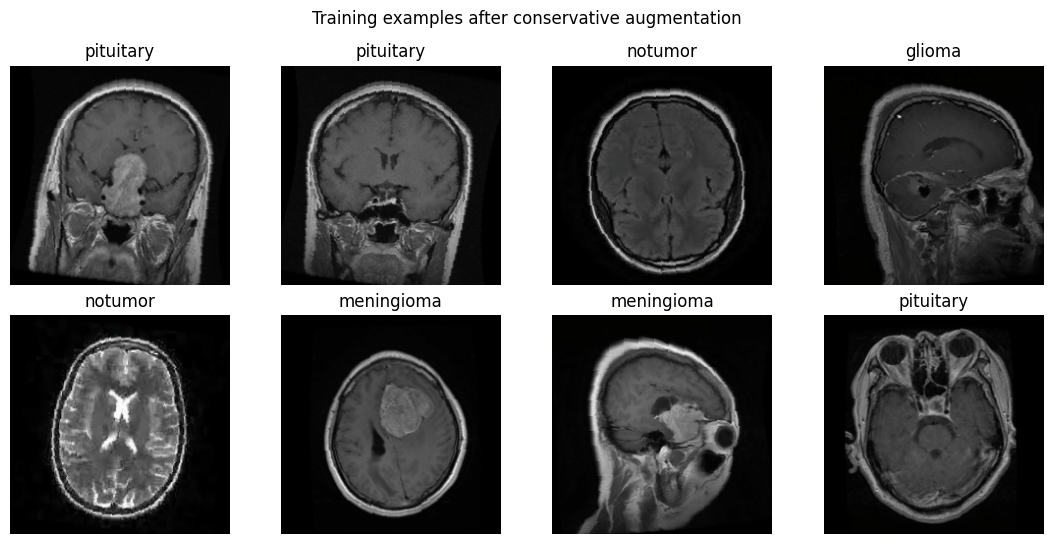

In [5]:
loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))
train_loader = DataLoader(train_dataset, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED), **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_args)

sample_images, sample_labels = next(iter(train_loader))
assert sample_images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
print('One batch:', tuple(sample_images.shape), sample_labels.tolist()[:10])

_mean = np.array(IMAGENET_MEAN).reshape(1, 1, 3)
_std = np.array(IMAGENET_STD).reshape(1, 1, 3)


def denormalize(tensor):
    return np.clip(tensor.detach().cpu().permute(1, 2, 0).numpy() * _std + _mean, 0, 1)


fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for ax, img, label in zip(axes.flat, sample_images[:8], sample_labels[:8]):
    ax.imshow(denormalize(img))
    ax.set_title(CLASS_NAMES[int(label)])
    ax.axis('off')
fig.suptitle('Training examples after conservative augmentation')
fig.tight_layout()
fig.savefig(WORK_DIR / f'samples_{TEAM_ID}.png', dpi=170, bbox_inches='tight')
plt.show()

## 5. Model builders and the training / evaluation loop

- `build_net` creates ResNet18 (deployed) or ResNet50 (architecture comparison) with a new 4-class `fc` layer.
- `set_trainable` freezes everything except the chosen blocks and `fc`.
- **BatchNorm statistics are kept frozen** (`freeze_bn_statistics`): with batch size 16 and highly correlated MRI slices, updating running statistics would be noisy. This also avoids the common bug of leaving BN in train mode while its parameters are frozen.
- Loss is averaged by the true batch size, validation runs without gradients, and the **best validation-loss checkpoint** of each stage is restored. The test set is never used for any decision.

In [6]:
def build_net(arch, pretrained=True):
    if arch == 'resnet18':
        net = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    elif arch == 'resnet50':
        net = models.resnet50(weights=ResNet50_Weights.IMAGENET1K_V1 if pretrained else None)
    else:
        raise ValueError(arch)
    net.fc = nn.Linear(net.fc.in_features, len(CLASS_NAMES))
    return net


def set_trainable(net, blocks):
    for p in net.parameters():
        p.requires_grad = False
    for name in list(blocks) + ['fc']:
        for p in getattr(net, name).parameters():
            p.requires_grad = True


def count_params(net, trainable_only=False):
    return sum(p.numel() for p in net.parameters() if (p.requires_grad or not trainable_only))


def freeze_bn_statistics(net):
    for layer in net.modules():
        if isinstance(layer, nn.modules.batchnorm._BatchNorm):
            layer.eval()


def cpu_state(net):
    return {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}


def sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()


criterion = nn.CrossEntropyLoss()


def run_epoch(net, loader, optimizer=None, scaler=None):
    training = optimizer is not None
    if training:
        net.train()
        freeze_bn_statistics(net)
    else:
        net.eval()

    loss_total, num_samples = 0.0, 0
    all_true, all_pred = [], []
    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            amp_context = torch.autocast('cuda', dtype=torch.float16) if USE_AMP else nullcontext()
            with amp_context:
                logits = net(images)
                loss = criterion(logits, targets)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        batch_count = targets.size(0)
        loss_total += loss.detach().item() * batch_count
        num_samples += batch_count
        all_true.extend(targets.detach().cpu().tolist())
        all_pred.extend(logits.detach().argmax(1).cpu().tolist())

    assert num_samples > 0
    macro_f1 = precision_recall_fscore_support(
        all_true, all_pred, labels=list(range(4)), average='macro', zero_division=0)[2]
    return {'loss': loss_total / num_samples,
            'accuracy': accuracy_score(all_true, all_pred),
            'macro_f1': float(macro_f1)}


def fit_stage(net, optimizer, *, stage, max_epochs, patience):
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    best_loss, best_state = float('inf'), cpu_state(net)
    history, stale_epochs = [], 0
    sync()
    start = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        train_stats = run_epoch(net, train_loader, optimizer, scaler)
        val_stats = run_epoch(net, val_loader)
        history.append({'stage': stage, 'epoch': epoch,
                        **{f'train_{k}': v for k, v in train_stats.items()},
                        **{f'val_{k}': v for k, v in val_stats.items()}})

        if val_stats['loss'] < best_loss - 1e-4:
            best_loss, best_state, stale_epochs = val_stats['loss'], cpu_state(net), 0
        else:
            stale_epochs += 1

        print(f'{stage:18s} epoch {epoch:02d}/{max_epochs:02d} | '
              f'train loss {train_stats["loss"]:.4f} acc {train_stats["accuracy"]:.3f} | '
              f'val loss {val_stats["loss"]:.4f} acc {val_stats["accuracy"]:.3f} '
              f'F1 {val_stats["macro_f1"]:.3f}')
        if stale_epochs >= patience:
            print(f'{stage}: early stopping (patience={patience})')
            break

    sync()
    elapsed = time.perf_counter() - start
    net.load_state_dict(best_state)
    net.eval()
    return pd.DataFrame(history), elapsed

## 6. Training-strategy, hyperparameter and architecture comparison (validation only)

Assignment §3.3 asks for at least two architectures, hyperparameter settings or training strategies. Every run below is selected and compared **only on the validation split**; the official `Testing/` folder is untouched.

| Experiment | Architecture | Trainable | Learning rates |
|---|---|---|---|
| `r18_head_only` | ResNet18 | `fc` | fc 1e-3 |
| `r18_layer4_lowLR` | ResNet18 | `layer4` + `fc` | 1e-5 / 1e-4 |
| `r18_layer4_highLR` | ResNet18 | `layer4` + `fc` | 1e-4 / 1e-3 |
| `r18_layer3+4` | ResNet18 | `layer3` + `layer4` + `fc` | 1e-5 / 5e-5 / 3e-4 |
| `r50_head_only` → `r50_layer4` | ResNet50 | `fc`, then `layer4` + `fc` | 1e-5 / 1e-4 |

All fine-tuning runs start from the same frozen-head checkpoint of their architecture, so the comparison is fair. ResNet50 is a comparison-only architecture; the **deployed model is chosen among the ResNet18 fine-tuning runs** (small, fast on CPU, the API is built for it).

In [7]:
experiments = {}


def register(name, arch, net, history, seconds, config, parent=None):
    val = run_epoch(net, val_loader)
    parent_seconds = experiments[parent]['total_seconds'] if parent else 0.0
    experiments[name] = {
        'arch': arch, 'state': cpu_state(net), 'history': history, 'val': val,
        'seconds': seconds, 'total_seconds': seconds + parent_seconds,
        'trainable_params': count_params(net, trainable_only=True),
        'total_params': count_params(net), 'config': config, 'parent': parent,
    }
    print(f'>> {name}: val loss {val["loss"]:.4f} | acc {val["accuracy"]:.4f} | '
          f'macro-F1 {val["macro_f1"]:.4f} | {seconds:.0f}s\n')


def train_head(arch, name):
    seed_everything(SEED)
    net = build_net(arch, pretrained=True).to(DEVICE)
    set_trainable(net, [])
    optimizer = torch.optim.AdamW(net.fc.parameters(), lr=1e-3, weight_decay=1e-4)
    history, seconds = fit_stage(net, optimizer, stage=name, max_epochs=HEAD_EPOCHS, patience=HEAD_PATIENCE)
    register(name, arch, net, history, seconds, {'trainable': ['fc'], 'lr': {'fc': 1e-3}, 'weight_decay': 1e-4})
    del net, optimizer
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()


def train_finetune(arch, name, parent, lrs):
    seed_everything(SEED)
    net = build_net(arch, pretrained=False).to(DEVICE)
    net.load_state_dict(experiments[parent]['state'])
    blocks = [b for b in lrs if b != 'fc']
    set_trainable(net, blocks)
    groups = [{'params': getattr(net, b).parameters(), 'lr': lrs[b]} for b in blocks]
    groups.append({'params': net.fc.parameters(), 'lr': lrs['fc']})
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-4)
    history, seconds = fit_stage(net, optimizer, stage=name, max_epochs=FINETUNE_EPOCHS,
                                 patience=FINETUNE_PATIENCE)
    register(name, arch, net, history, seconds,
             {'trainable': blocks + ['fc'], 'lr': lrs, 'weight_decay': 1e-4}, parent=parent)
    del net, optimizer
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()


# --- ResNet18: frozen baseline, then three fine-tuning variants ---
train_head('resnet18', 'r18_head_only')
R18_FINETUNE = {
    'r18_layer4_lowLR':  {'layer4': 1e-5, 'fc': 1e-4},
    'r18_layer4_highLR': {'layer4': 1e-4, 'fc': 1e-3},
    'r18_layer3+4':      {'layer3': 1e-5, 'layer4': 5e-5, 'fc': 3e-4},
}
for exp_name, lrs in R18_FINETUNE.items():
    train_finetune('resnet18', exp_name, parent='r18_head_only', lrs=lrs)

# --- ResNet50: architecture comparison ---
if RUN_RESNET50_COMPARISON:
    train_head('resnet50', 'r50_head_only')
    train_finetune('resnet50', 'r50_layer4', parent='r50_head_only', lrs={'layer4': 1e-5, 'fc': 1e-4})

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Ahmed Kazak/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:14<00:00, 3.26MB/s]


r18_head_only      epoch 01/06 | train loss 0.6413 acc 0.761 | val loss 0.4564 acc 0.859 F1 0.858
r18_head_only      epoch 02/06 | train loss 0.3959 acc 0.865 | val loss 0.3882 acc 0.871 F1 0.873
r18_head_only      epoch 03/06 | train loss 0.3575 acc 0.870 | val loss 0.3800 acc 0.870 F1 0.872
r18_head_only      epoch 04/06 | train loss 0.3294 acc 0.882 | val loss 0.3293 acc 0.882 F1 0.882
r18_head_only      epoch 05/06 | train loss 0.3099 acc 0.887 | val loss 0.3293 acc 0.887 F1 0.885
r18_head_only      epoch 06/06 | train loss 0.3046 acc 0.890 | val loss 0.3235 acc 0.886 F1 0.884
>> r18_head_only: val loss 0.3235 | acc 0.8857 | macro-F1 0.8839 | 355s

r18_layer4_lowLR   epoch 01/12 | train loss 0.2592 acc 0.904 | val loss 0.2283 acc 0.920 F1 0.919
r18_layer4_lowLR   epoch 02/12 | train loss 0.1772 acc 0.936 | val loss 0.1759 acc 0.940 F1 0.940
r18_layer4_lowLR   epoch 03/12 | train loss 0.1450 acc 0.946 | val loss 0.1998 acc 0.932 F1 0.930
r18_layer4_lowLR   epoch 04/12 | train loss 0

100%|██████████| 97.8M/97.8M [00:32<00:00, 3.14MB/s]


r50_head_only      epoch 01/06 | train loss 0.5862 acc 0.773 | val loss 0.4195 acc 0.849 F1 0.852
r50_head_only      epoch 02/06 | train loss 0.3841 acc 0.858 | val loss 0.3531 acc 0.858 F1 0.857
r50_head_only      epoch 03/06 | train loss 0.3367 acc 0.876 | val loss 0.3849 acc 0.837 F1 0.842
r50_head_only      epoch 04/06 | train loss 0.3168 acc 0.886 | val loss 0.3359 acc 0.883 F1 0.883
r50_head_only      epoch 05/06 | train loss 0.2921 acc 0.897 | val loss 0.3115 acc 0.890 F1 0.890
r50_head_only      epoch 06/06 | train loss 0.2982 acc 0.889 | val loss 0.3176 acc 0.882 F1 0.883
>> r50_head_only: val loss 0.3115 | acc 0.8902 | macro-F1 0.8899 | 206s

r50_layer4         epoch 01/12 | train loss 0.2536 acc 0.909 | val loss 0.2157 acc 0.916 F1 0.917
r50_layer4         epoch 02/12 | train loss 0.1671 acc 0.939 | val loss 0.1695 acc 0.940 F1 0.940
r50_layer4         epoch 03/12 | train loss 0.1168 acc 0.959 | val loss 0.1755 acc 0.935 F1 0.936
r50_layer4         epoch 04/12 | train loss 0

## 7. Comparison table and model selection

The deployment candidate is the ResNet18 fine-tuning run with the **lowest validation loss** (ties are unlikely; macro-F1 is shown for reference). Cumulative time includes the frozen-head stage the run started from.

,experiment,architecture,trainable_params,epochs_run,val_loss,val_accuracy,val_macro_f1,stage_seconds,cumulative_seconds
0,r18_head_only,resnet18,"2,052",6,0.3235,0.8857,0.8839,354.700000,354.700000
1,r18_layer4_lowLR,resnet18,"8,395,780",12,0.1169,0.9625,0.9627,954.300000,1309.000000
2,r18_layer4_highLR,resnet18,"8,395,780",10,0.1168,0.9670,0.9667,349.200000,703.900000
3,r18_layer3+4,resnet18,"10,495,492",9,0.0825,0.9777,0.9776,307.100000,661.800000
4,r50_head_only,resnet50,"8,196",6,0.3115,0.8902,0.8899,206.100000,206.100000
5,r50_layer4,resnet50,"14,972,932",6,0.1695,0.9402,0.9403,215.200000,421.300000


Selected for deployment (lowest validation loss among ResNet18 fine-tuning runs): r18_layer3+4
Config: {'trainable': ['layer3', 'layer4', 'fc'], 'lr': {'layer3': 1e-05, 'layer4': 5e-05, 'fc': 0.0003}, 'weight_decay': 0.0001}


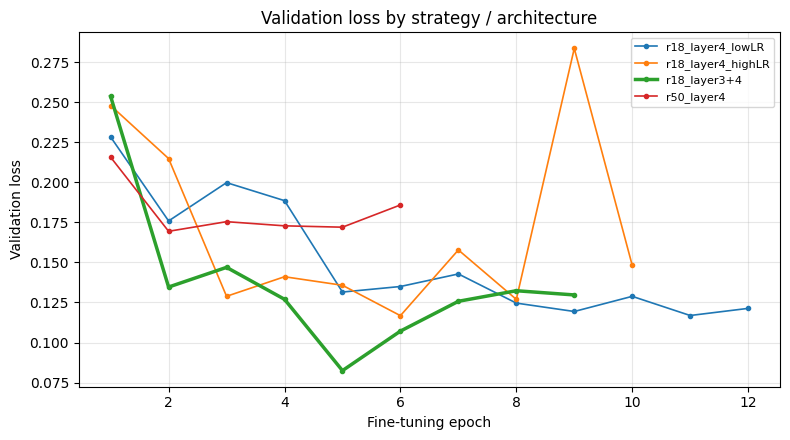

In [8]:
rows = []
for name, e in experiments.items():
    rows.append({
        'experiment': name, 'architecture': e['arch'],
        'trainable_params': e['trainable_params'],
        'epochs_run': len(e['history']),
        'val_loss': e['val']['loss'], 'val_accuracy': e['val']['accuracy'],
        'val_macro_f1': e['val']['macro_f1'],
        'stage_seconds': round(e['seconds'], 1),
        'cumulative_seconds': round(e['total_seconds'], 1),
    })
comparison = pd.DataFrame(rows)
display(comparison.style.format({'val_loss': '{:.4f}', 'val_accuracy': '{:.4f}', 'val_macro_f1': '{:.4f}',
                                 'trainable_params': '{:,}'}))
comparison.to_csv(WORK_DIR / f'strategy_comparison_{TEAM_ID}.csv', index=False)

deploy_candidates = [n for n, e in experiments.items()
                     if e['arch'] == 'resnet18' and e['parent'] is not None]
final_name = min(deploy_candidates, key=lambda n: experiments[n]['val']['loss'])
final_exp = experiments[final_name]
print('Selected for deployment (lowest validation loss among ResNet18 fine-tuning runs):', final_name)
print('Config:', final_exp['config'])

final_model = build_net('resnet18', pretrained=False)
final_model.load_state_dict(final_exp['state'])
final_model = final_model.to(DEVICE).eval()

# ---- validation-loss curves of every fine-tuning run ----
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, e in experiments.items():
    if e['parent'] is None:
        continue
    h = e['history']
    ax.plot(h['epoch'], h['val_loss'], marker='o', ms=3, label=name,
            lw=2.5 if name == final_name else 1.2)
ax.set(xlabel='Fine-tuning epoch', ylabel='Validation loss', title='Validation loss by strategy / architecture')
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(WORK_DIR / f'strategy_val_loss_{TEAM_ID}.png', dpi=170, bbox_inches='tight')
plt.show()

## 8. Learning curves of the selected model

Epochs of the frozen-head stage are followed by the epochs of the selected fine-tuning run; the dashed line marks where fine-tuning starts.

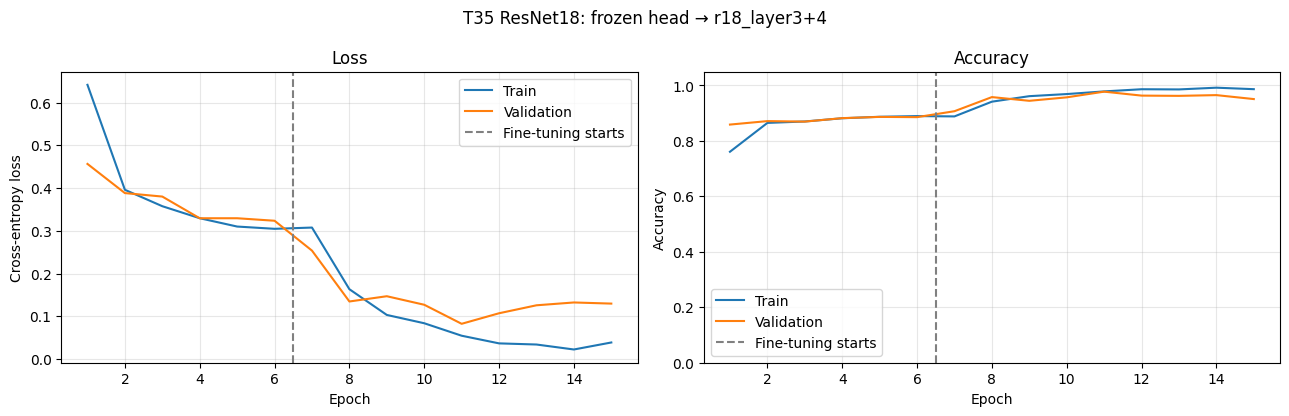

Saved: C:\Users\Ahmed Kazak\AI_Security\T35_work\learning_curves_T35.png


In [9]:
head_history = experiments['r18_head_only']['history']
history = pd.concat([head_history, final_exp['history']], ignore_index=True)
history['global_epoch'] = np.arange(1, len(history) + 1)
history.to_csv(WORK_DIR / f'history_{TEAM_ID}.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
panels = [('loss', 'Cross-entropy loss', 'Loss'), ('accuracy', 'Accuracy', 'Accuracy')]
for ax, (metric, ylabel, title) in zip(axes, panels):
    ax.plot(history['global_epoch'], history[f'train_{metric}'], label='Train')
    ax.plot(history['global_epoch'], history[f'val_{metric}'], label='Validation')
    ax.axvline(len(head_history) + 0.5, color='gray', ls='--', label='Fine-tuning starts')
    ax.set(xlabel='Epoch', ylabel=ylabel, title=title)
    ax.grid(alpha=0.3)
    ax.legend()
axes[1].set_ylim(0, 1.05)
fig.suptitle(f'T35 ResNet18: frozen head → {final_name}')
fig.tight_layout()
curves_path = WORK_DIR / f'learning_curves_{TEAM_ID}.png'
fig.savefig(curves_path, dpi=170, bbox_inches='tight')
plt.show()
print('Saved:', curves_path)

## 9. Export the model as `model/model_T35.pt`

The deployed model is a plain ResNet18 with `fc: Linear(512, 4)`. The file is a **CPU `state_dict`** that FastAPI can load offline with `weights=None` and `weights_only=True`. Preprocessing metadata is saved **outside** the repo (`T35_work/`); hardcode the same values in `app/config.py` / `app/main.py`.

The reloaded CPU model must agree with the GPU model on the same image.

In [10]:
torch.save(final_exp['state'], MODEL_PATH)

metadata = {
    'team_id': TEAM_ID,
    'framework': 'pytorch',
    'architecture': 'torchvision.models.resnet18',
    'num_classes': len(CLASS_NAMES),
    'class_names': CLASS_NAMES,
    'image_size': IMAGE_SIZE,
    'color_mode': 'RGB',
    'resize': 'Resize((224, 224), InterpolationMode.BILINEAR)',
    'pixel_scale': 'ToTensor(): uint8 -> float32 in [0, 1]',
    'normalization_mean': list(IMAGENET_MEAN),
    'normalization_std': list(IMAGENET_STD),
    'selected_experiment': final_name,
    'selected_config': final_exp['config'],
    'selection_rule': 'minimum validation cross-entropy among ResNet18 fine-tuning runs',
    'seed': SEED,
    'environment': ENVIRONMENT,
    'created_utc': datetime.now(timezone.utc).isoformat(),
}
(WORK_DIR / f'metadata_{TEAM_ID}.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')

# Reload on CPU with no pretrained download and compare with the in-memory model.
reloaded_cpu = build_net('resnet18', pretrained=False)
reloaded_cpu.load_state_dict(torch.load(MODEL_PATH, map_location='cpu', weights_only=True))
reloaded_cpu.eval()
with torch.inference_mode():
    image_cpu = val_dataset[0][0].unsqueeze(0)
    original_logits = final_model(image_cpu.to(DEVICE)).cpu()
    exported_logits = reloaded_cpu(image_cpu)
    torch.testing.assert_close(original_logits, exported_logits, atol=1e-2, rtol=1e-2)
    assert original_logits.argmax(1).item() == exported_logits.argmax(1).item()

model_size_mib = MODEL_PATH.stat().st_size / 2**20
print('Saved model:', MODEL_PATH, '| MiB:', round(model_size_mib, 2))
print('CPU reload / logit agreement: PASSED')

Saved model: C:\Users\Ahmed Kazak\AI_Security\brain-tumor-detection\model\model_T35.pt | MiB: 42.71
CPU reload / logit agreement: PASSED


## 10. Evaluate the unseen Testing split (once, after model selection)

Class-level precision / recall / F1, macro and weighted averages, accuracy and the confusion matrix. **Do not change the model after looking at these numbers.**

Held-out test inference: 100%|██████████| 100/100 [00:10<00:00,  9.99it/s]


{
  "selected_experiment": "r18_layer3+4",
  "accuracy": 0.93375,
  "precision_macro": 0.9381086568654486,
  "recall_macro": 0.9337500000000001,
  "f1_macro": 0.932713511120669,
  "precision_weighted": 0.9381086568654484,
  "recall_weighted": 0.93375,
  "f1_weighted": 0.9327135111206691,
  "num_test_images": 1600,
  "num_misclassified": 106,
  "head_seconds": 354.705,
  "finetune_seconds": 307.137,
  "training_seconds": 661.842,
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 3050 Ti Laptop GPU"
}

Per-class test report:

              precision    recall  f1-score   support

      glioma     0.9787    0.8050    0.8834       400
  meningioma     0.8810    0.9625    0.9200       400
     notumor     0.9029    1.0000    0.9490       400
   pituitary     0.9898    0.9675    0.9785       400

    accuracy                         0.9337      1600
   macro avg     0.9381    0.9338    0.9327      1600
weighted avg     0.9381    0.9337    0.9327      1600



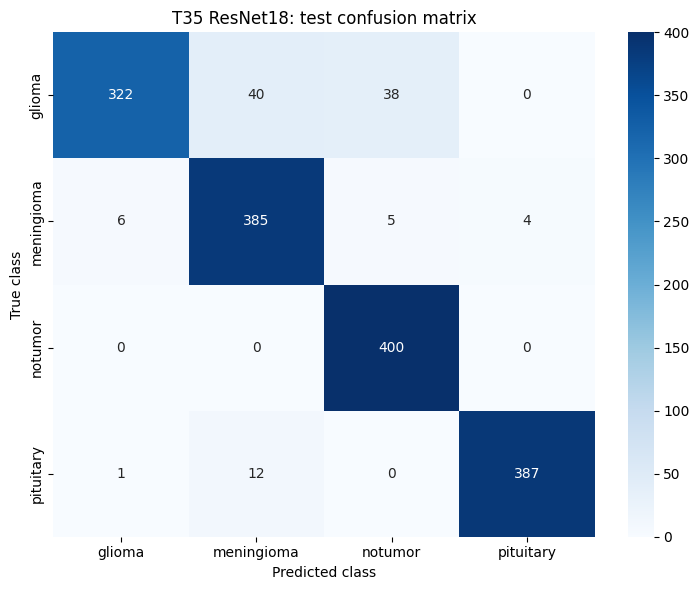

106 misclassified test images listed in misclassified_T35.csv


In [11]:
@torch.inference_mode()
def collect_predictions(net, loader):
    net.eval()
    truths, predictions, probabilities = [], [], []
    for images, targets in tqdm(loader, desc='Held-out test inference'):
        outputs = net(images.to(DEVICE, non_blocking=True))
        probs = torch.softmax(outputs.float(), dim=1).cpu().numpy()
        truths.extend(targets.numpy().tolist())
        predictions.extend(probs.argmax(1).tolist())
        probabilities.extend(probs.tolist())
    return np.array(truths), np.array(predictions), np.array(probabilities)


y_true, y_pred, y_proba = collect_predictions(final_model, test_loader)
assert len(y_true) == len(test_dataset)
assert y_proba.shape == (len(test_dataset), len(CLASS_NAMES))
assert np.allclose(y_proba.sum(axis=1), 1.0, atol=1e-4)

precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_true, y_pred, labels=list(range(4)), average='macro', zero_division=0)
precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
    y_true, y_pred, labels=list(range(4)), average='weighted', zero_division=0)

metrics = {
    'selected_experiment': final_name,
    'accuracy': float(accuracy_score(y_true, y_pred)),
    'precision_macro': float(precision_macro), 'recall_macro': float(recall_macro), 'f1_macro': float(f1_macro),
    'precision_weighted': float(precision_weighted), 'recall_weighted': float(recall_weighted),
    'f1_weighted': float(f1_weighted),
    'num_test_images': int(len(y_true)),
    'num_misclassified': int((y_true != y_pred).sum()),
    'head_seconds': round(experiments['r18_head_only']['seconds'], 3),
    'finetune_seconds': round(final_exp['seconds'], 3),
    'training_seconds': round(final_exp['total_seconds'], 3),
    'device': str(DEVICE), 'gpu': ENVIRONMENT['gpu'],
}
print(json.dumps(metrics, indent=2))
print('\nPer-class test report:\n')
print(classification_report(y_true, y_pred, labels=list(range(4)),
                            target_names=CLASS_NAMES, digits=4, zero_division=0))

conf = confusion_matrix(y_true, y_pred, labels=list(range(4)))
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set(xlabel='Predicted class', ylabel='True class', title='T35 ResNet18: test confusion matrix')
fig.tight_layout()
fig.savefig(WORK_DIR / f'confusion_matrix_{TEAM_ID}.png', dpi=170, bbox_inches='tight')
plt.show()

(WORK_DIR / f'metrics_{TEAM_ID}.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')

wrong_idx = np.where(y_true != y_pred)[0]
pd.DataFrame({
    'file': [Path(test_dataset.samples[i][0]).relative_to(TEST_DIR).as_posix() for i in wrong_idx],
    'true': [CLASS_NAMES[y_true[i]] for i in wrong_idx],
    'predicted': [CLASS_NAMES[y_pred[i]] for i in wrong_idx],
    'confidence': [float(y_proba[i].max()) for i in wrong_idx],
}).to_csv(WORK_DIR / f'misclassified_{TEAM_ID}.csv', index=False)
print(f'{len(wrong_idx)} misclassified test images listed in misclassified_{TEAM_ID}.csv')

## 11. Grad-CAM (mandatory interpretability)

Grad-CAM on the last residual block (`layer4[-1]`): channel weights are the spatially averaged gradients of the **predicted class** score, followed by ReLU and upsampling to the input size. The figure shows one correct example per class and then misclassified examples (if any).

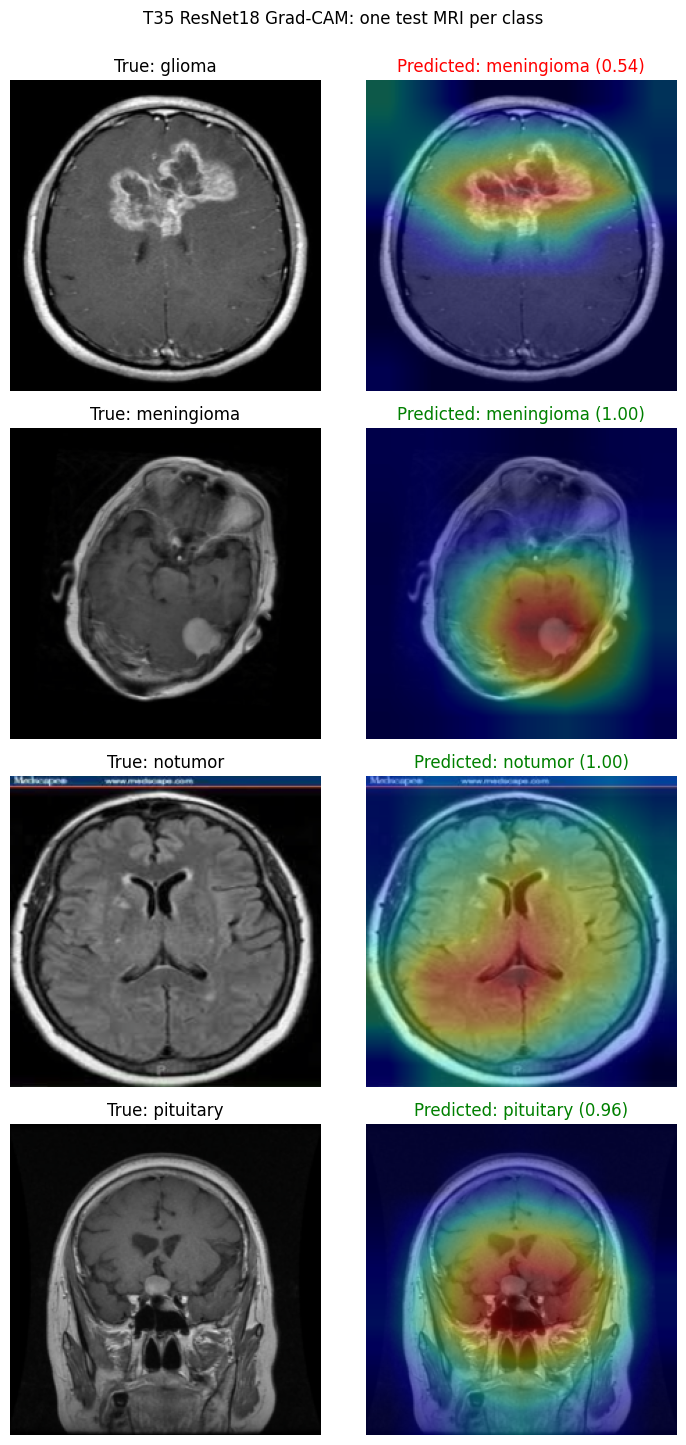

Saved: C:\Users\Ahmed Kazak\AI_Security\T35_work\gradcam_T35.png


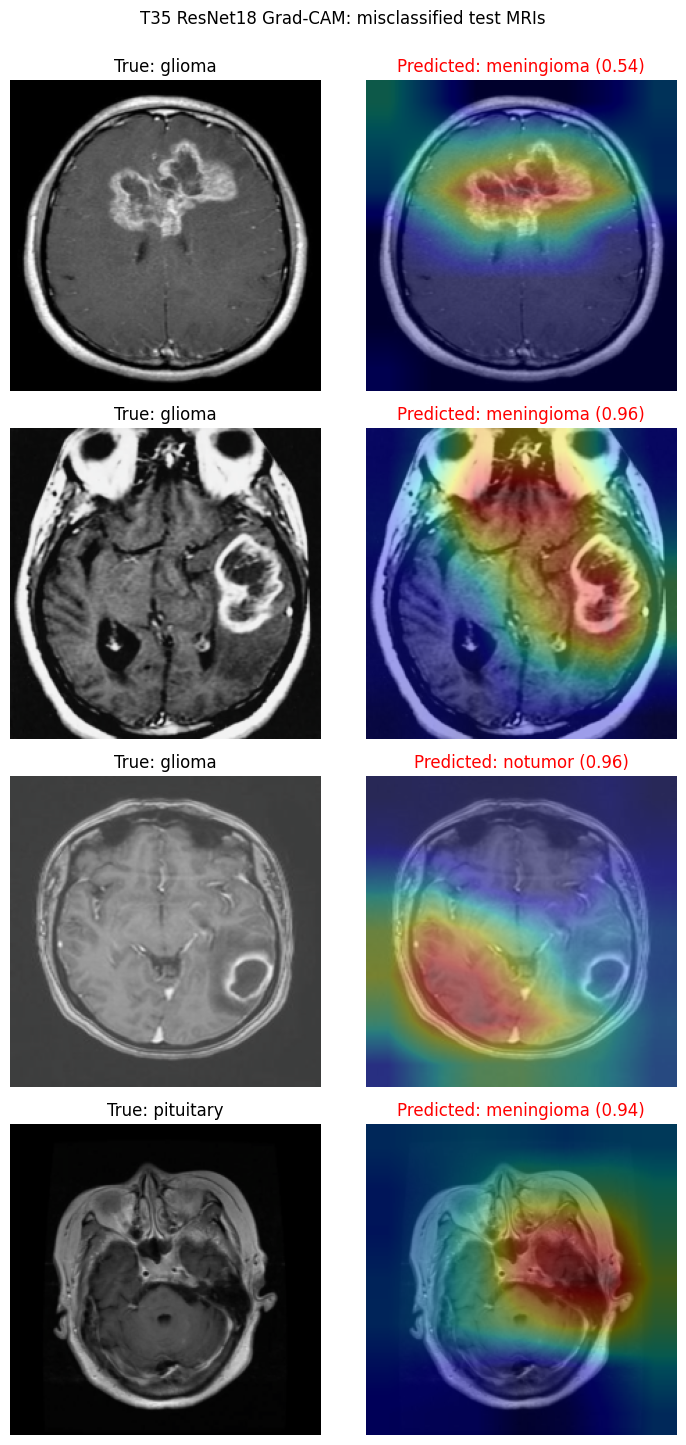

Saved: C:\Users\Ahmed Kazak\AI_Security\T35_work\gradcam_errors_T35.png


In [12]:
def make_grad_cam(net, image_batch, class_index=None):
    net.eval()
    captured = {}
    image_batch = image_batch.detach().clone().requires_grad_(True)  # gradients even if weights are frozen

    def capture_activation(_module, _inputs, output):
        captured['features'] = output
        output.retain_grad()

    hook = net.layer4[-1].register_forward_hook(capture_activation)
    try:
        net.zero_grad(set_to_none=True)
        logits = net(image_batch)
        selected = int(logits.argmax(1).item()) if class_index is None else int(class_index)
        probability = float(torch.softmax(logits.detach(), dim=1)[0, selected])
        logits[0, selected].backward()
        feats = captured['features']
        grads = feats.grad
        assert grads is not None
        weights = grads.mean(dim=(2, 3), keepdim=True)
        heat = torch.relu((weights * feats).sum(dim=1, keepdim=True))
        heat = F.interpolate(heat, size=image_batch.shape[-2:], mode='bilinear', align_corners=False)
        heat = heat[0, 0].detach().float().cpu().numpy()
        heat -= heat.min()
        heat /= max(float(heat.max()), 1e-8)
        return heat, selected, probability
    finally:
        hook.remove()


def cam_overlay(rgb_image, heat):
    colors = plt.get_cmap('jet')(heat)[..., :3]
    return np.clip(0.65 * rgb_image + 0.35 * colors, 0, 1)


def show_cam_grid(sample_indices, title, path):
    rows = len(sample_indices)
    fig, axes = plt.subplots(rows, 2, figsize=(7.5, 3.6 * rows), squeeze=False)
    for r, idx in enumerate(sample_indices):
        image_tensor, true_class = test_dataset[int(idx)]
        cam, predicted, prob = make_grad_cam(final_model, image_tensor.unsqueeze(0).to(DEVICE))
        img = denormalize(image_tensor)
        axes[r, 0].imshow(img)
        axes[r, 0].set_title(f'True: {CLASS_NAMES[true_class]}')
        axes[r, 1].imshow(cam_overlay(img, cam))
        axes[r, 1].set_title(f'Predicted: {CLASS_NAMES[predicted]} ({prob:.2f})',
                             color='green' if predicted == true_class else 'red')
        axes[r, 0].axis('off')
        axes[r, 1].axis('off')
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    fig.savefig(path, dpi=170, bbox_inches='tight')
    plt.show()
    print('Saved:', path)


# One deterministic correct-class example per class (first test image of each class).
class_examples = [next(i for i, y in enumerate(test_dataset.targets) if y == c) for c in range(4)]
show_cam_grid(class_examples, 'T35 ResNet18 Grad-CAM: one test MRI per class',
              WORK_DIR / f'gradcam_{TEAM_ID}.png')

# Evenly spaced misclassified examples (for the error-analysis paragraph in the report).
if len(wrong_idx) > 0:
    pick = wrong_idx[np.linspace(0, len(wrong_idx) - 1, min(4, len(wrong_idx))).astype(int)]
    show_cam_grid(pick, 'T35 ResNet18 Grad-CAM: misclassified test MRIs',
                  WORK_DIR / f'gradcam_errors_{TEAM_ID}.png')
else:
    print('No misclassified test images, so there is no error Grad-CAM to show.')

## 12. Offline single-image CPU inference and deployment statistics

`predict_cpu_pil` mirrors what `POST /predict` must do: open the bytes as a PIL image, convert to RGB, apply `eval_transform`, run the **reloaded CPU model** and softmax. `confidence` is the maximum softmax probability, **not** a calibrated clinical confidence.

In [13]:
@torch.inference_mode()
def predict_cpu_pil(pil_image):
    x = eval_transform(pil_image.convert('RGB')).unsqueeze(0)
    probs = torch.softmax(reloaded_cpu(x), dim=1)[0].tolist()
    assert abs(sum(probs) - 1) < 1e-5
    best = int(np.argmax(probs))
    return {
        'framework': 'pytorch',
        'label': CLASS_NAMES[best],
        'confidence': float(probs[best]),
        'probabilities': {name: float(probs[i]) for i, name in enumerate(CLASS_NAMES)},
    }


example_path = Path(test_dataset.samples[0][0])
with Image.open(example_path) as original:
    prediction = predict_cpu_pil(original)
print('Example file:', example_path.name)
print(json.dumps(prediction, indent=2))

# ---- CPU latency benchmark (preprocessing + forward) ----
with Image.open(example_path) as original:
    bench_image = original.convert('RGB').copy()
for _ in range(5):                       # warm-up
    predict_cpu_pil(bench_image)
timings = []
for _ in range(50):
    t0 = time.perf_counter()
    predict_cpu_pil(bench_image)
    timings.append((time.perf_counter() - t0) * 1000)

deployment_stats = {
    'model_file_mib': round(model_size_mib, 2),
    'total_parameters': count_params(reloaded_cpu),
    'cpu_threads': torch.get_num_threads(),
    'latency_ms_mean': round(float(np.mean(timings)), 1),
    'latency_ms_median': round(float(np.median(timings)), 1),
    'latency_ms_p95': round(float(np.percentile(timings, 95)), 1),
    'runs': len(timings),
}
print('\nCPU deployment statistics:')
print(json.dumps(deployment_stats, indent=2))
(WORK_DIR / f'deployment_stats_{TEAM_ID}.json').write_text(json.dumps(deployment_stats, indent=2), encoding='utf-8')

Example file: Te-gl_1.jpg
{
  "framework": "pytorch",
  "label": "meningioma",
  "confidence": 0.539142906665802,
  "probabilities": {
    "glioma": 0.009150476194918156,
    "meningioma": 0.539142906665802,
    "notumor": 0.3940434157848358,
    "pituitary": 0.057663194835186005
  }
}

CPU deployment statistics:
{
  "model_file_mib": 42.71,
  "total_parameters": 11178564,
  "cpu_threads": 8,
  "latency_ms_mean": 25.9,
  "latency_ms_median": 26.3,
  "latency_ms_p95": 31.1,
  "runs": 50
}


177